# Etapa 4 — Classificação ABC-XYZ

**Projeto:** Planejamento da Cadeia de Suprimentos  
**Objetivo:** Priorizar produtos com base em valor de consumo (ABC) e variabilidade da demanda (XYZ), gerando políticas diferenciadas de reposição para cada quadrante da matriz.

---

## 1. Carregamento dos Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv("data/base_tratada.csv")
df['data_pedido'] = pd.to_datetime(df['data_pedido'])

print(f'Registros: {df.shape[0]:,} | Produtos únicos: {df["id_produto"].nunique()}')

Registros: 49,890 | Produtos únicos: 20


## 2. Classificação ABC — Por Valor de Consumo

Lógica:
- **A**: top 20% dos produtos que representam ~80% do valor total (Lei de Pareto)
- **B**: próximos 30% dos produtos (~15% do valor)
- **C**: demais 50% dos produtos (~5% do valor)

In [2]:
# Valor total consumido por produto
valor_produto = (
    df.groupby(['id_produto', 'produto', 'categoria'])
    ['valor_total_pedido']
    .sum()
    .reset_index()
    .rename(columns={'valor_total_pedido': 'valor_total'})
    .sort_values('valor_total', ascending=False)
    .reset_index(drop=True)
)

# Participação acumulada
valor_total_geral = valor_produto['valor_total'].sum()
valor_produto['pct_valor']      = valor_produto['valor_total'] / valor_total_geral
valor_produto['pct_valor_acum'] = valor_produto['pct_valor'].cumsum()
valor_produto['rank_pct']       = (valor_produto.index + 1) / len(valor_produto)

# Atribuir classe ABC
def classifica_abc(pct_acum):
    if pct_acum <= 0.80:
        return 'A'
    elif pct_acum <= 0.95:
        return 'B'
    else:
        return 'C'

valor_produto['classe_abc'] = valor_produto['pct_valor_acum'].apply(classifica_abc)

# Resumo
resumo_abc = valor_produto.groupby('classe_abc').agg(
    qtd_produtos=('id_produto', 'count'),
    valor_total=('valor_total', 'sum')
).assign(
    pct_produtos=lambda x: x['qtd_produtos'] / len(valor_produto),
    pct_valor=lambda x: x['valor_total'] / valor_total_geral
)
print('=== Resumo ABC ===')
display(resumo_abc.round(3).style.format({'valor_total': '{:,.0f}'}))

=== Resumo ABC ===


,qtd_produtos,valor_total,pct_produtos,pct_valor
classe_abc,,,,
A,7,"131,356,986",0.350000,0.786000
B,6,"25,300,219",0.300000,0.151000
C,7,"10,545,561",0.350000,0.063000


## Curva ABC — Análise de Valor por Produto

### Resumo dos Resultados

| Classe | Qtd. Produtos | % Produtos | Valor Total (R$) | % do Valor |
|--------|:-------------:|:----------:|:----------------:|:----------:|
| A      | 7             | 35%        | 131.356.986      | 78,6%      |
| B      | 6             | 30%        | 25.300.219       | 15,1%      |
| C      | 7             | 35%        | 10.545.561       | 6,3%       |
| **Total** | **20**     | **100%**   | **167.202.766**  | **100%**   |

---

### Interpretação Gerencial

**Classe A — Produtos Críticos**
- Apenas **7 produtos (35% do portfólio)** respondem por **78,6% do valor total consumido**.
- São os itens de maior impacto financeiro — qualquer ruptura ou ineficiência
  nesse grupo representa risco direto ao resultado.
- **Ação:** gestão de estoque rigorosa, revisão frequente de demanda,
  contratos de fornecimento prioritários e estoque de segurança elevado.

**Classe B — Produtos Intermediários**
- **6 produtos (30%)** representam **15,1% do valor**.
- Relevância moderada — devem ser monitorados para evitar migração para a Classe C
  ou para identificar oportunidades de promoção à Classe A.
- **Ação:** revisão periódica de demanda e política de reposição padrão.

**Classe C — Produtos de Baixo Impacto**
- **7 produtos (35%)** respondem por apenas **6,3% do valor total**.
- Consomem recursos operacionais desproporcionais ao retorno financeiro gerado.
- **Ação:** avaliar consolidação de pedidos, redução de frequência de reposição
  ou até descontinuação de itens com baixíssimo giro.

---

### Conclusão

> **35% dos produtos concentram quase 80% do valor** — padrão clássico de Pareto (80/20).
> O foco de gestão deve recair integralmente sobre os **7 produtos Classe A**,
> pois são eles que determinam a saúde financeira e operacional da cadeia de suprimentos.

## Curva de Pareto — Classificação ABC (Visual)


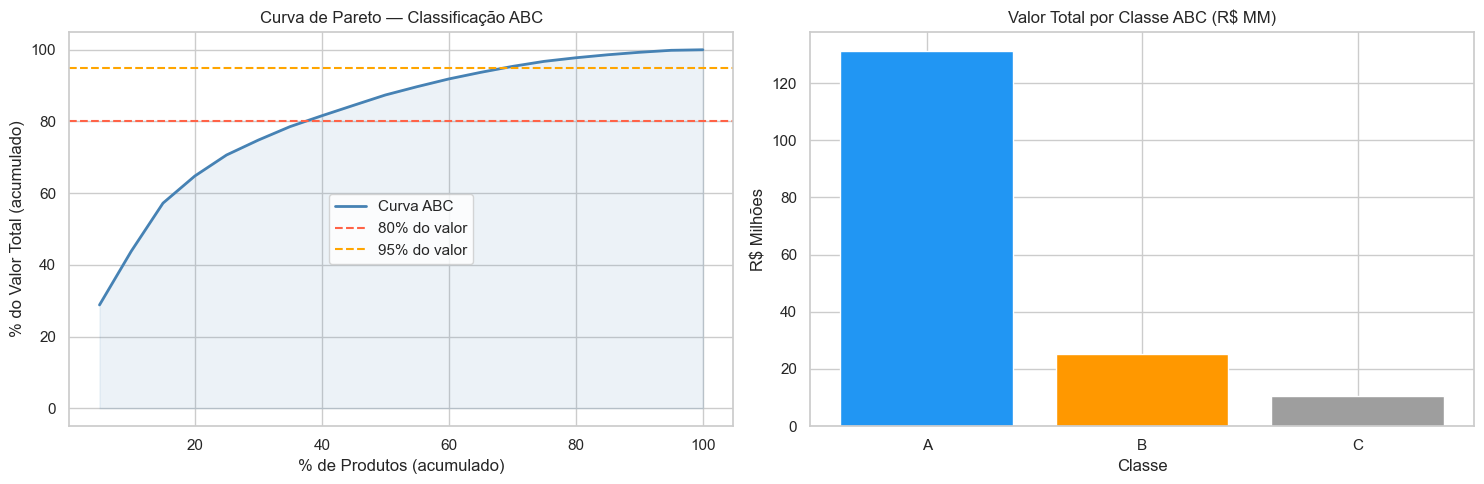

In [3]:
# Curva de Pareto
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Curva ABC
axes[0].plot(valor_produto['rank_pct'] * 100, valor_produto['pct_valor_acum'] * 100,
             color='steelblue', lw=2, label='Curva ABC')
axes[0].axhline(80, color='tomato', ls='--', label='80% do valor')
axes[0].axhline(95, color='orange', ls='--', label='95% do valor')
axes[0].fill_between(valor_produto['rank_pct'] * 100,
                      valor_produto['pct_valor_acum'] * 100, alpha=0.1, color='steelblue')
axes[0].set_title('Curva de Pareto — Classificação ABC')
axes[0].set_xlabel('% de Produtos (acumulado)')
axes[0].set_ylabel('% do Valor Total (acumulado)')
axes[0].legend()

# Distribuição ABC por valor
cores_abc = {'A': '#2196F3', 'B': '#FF9800', 'C': '#9E9E9E'}
for classe in ['A', 'B', 'C']:
    sub = valor_produto[valor_produto['classe_abc'] == classe]
    axes[1].bar(classe, sub['valor_total'].sum() / 1e6, color=cores_abc[classe], label=classe)
axes[1].set_title('Valor Total por Classe ABC (R$ MM)')
axes[1].set_ylabel('R$ Milhões')
axes[1].set_xlabel('Classe')

plt.tight_layout()
plt.show()

## Curva de Pareto — Classificação ABC (Visual)

---

### Gráfico 1 — Curva de Pareto Acumulada

**Observações:**
- A curva sobe de forma acentuada nos primeiros ~35% de produtos,
  atingindo **~80% do valor acumulado** rapidamente — comportamento
  típico de uma distribuição de Pareto bem definida.
- A linha **vermelha (80%)** é cruzada com apenas ~35% dos produtos
  no eixo X → confirma matematicamente a **Classe A**.
- A linha **amarela (95%)** é atingida com aproximadamente **65% dos produtos**
  → define o limite entre Classe B e C.
- A cauda da curva (60%–100% dos produtos) é quase plana,
  confirmando que os últimos 35% do portfólio (Classe C)
  agregam menos de **5% do valor incremental**.

---

### Gráfico 2 — Valor Total por Classe ABC (R$ MM)

| Classe | Valor Total (aprox.) | Visualização      |
|--------|----------------------|-------------------|
| A      | ~R$ 131 MM           | Barra dominante   |
| B      | ~R$ 25 MM            | 5x menor que A    |
| C      | ~R$ 10 MM            | 13x menor que A   |

**Observações:**
- A disparidade visual é impactante: a **barra A é massivamente maior**
  que B e C juntas (~R$ 35 MM combinados vs. ~R$ 131 MM da Classe A).
- A Classe B vale aproximadamente **2,5x a Classe C** —
  gap relevante que justifica tratamentos de gestão distintos entre elas.

---

### Conclusão Visual

> A curva confirma o **princípio de Pareto de forma clara e clássica**:
> poucos produtos (Classe A) dominam o valor total do portfólio.
> A gestão deve ser **inversamente proporcional ao número de itens** —
> máxima atenção nos 7 produtos A, atenção moderada nos 6 produtos B,
> e gestão simplificada/automatizada para os 7 produtos C.

## 3. Classificação XYZ — Por Variabilidade da Demanda
### Coeficiente de Variação (CV)

### Fórmula

$$CV = \frac{\sigma}{\mu} \times 100$$

Onde:
- $\sigma$ = desvio padrão da demanda no período
- $\mu$ = média da demanda no período
- Resultado expresso em **%**

---

### Explicação

O CV mede o **quanto a demanda varia em relação à sua própria média**.
Quanto maior o CV, mais instável e imprevisível é o comportamento do item.

Diferente do desvio padrão isolado, o CV é **adimensional** — permite
comparar a variabilidade entre produtos com escalas de demanda completamente
diferentes.

---

### Critérios de Classificação XYZ

| Classe | Intervalo de CV | Perfil                  |
|:------:|:---------------:|-------------------------|
| X      | CV < 20%        | Demanda estável          |
| Y      | 20% ≤ CV < 50%  | Demanda moderadamente variável |
| Z      | CV ≥ 50%        | Demanda imprevisível     |

In [4]:
# Demanda mensal por produto
demanda_mensal = (
    df.groupby(['id_produto', 'produto', 'ano', 'mes'])['quantidade_pedida']
    .sum()
    .reset_index()
)

# Coeficiente de variação por produto
cv_produto = (
    demanda_mensal.groupby(['id_produto', 'produto'])['quantidade_pedida']
    .agg(['mean', 'std'])
    .reset_index()
    .rename(columns={'mean': 'demanda_media', 'std': 'demanda_std'})
)
cv_produto['demanda_std'] = cv_produto['demanda_std'].fillna(0)
cv_produto['cv'] = cv_produto['demanda_std'] / cv_produto['demanda_media'].replace(0, np.nan)
cv_produto['cv'] = cv_produto['cv'].fillna(0)

def classifica_xyz(cv):
    if cv < 0.20:
        return 'X'
    elif cv < 0.50:
        return 'Y'
    else:
        return 'Z'

cv_produto['classe_xyz'] = cv_produto['cv'].apply(classifica_xyz)

print('=== Resumo XYZ ===')
resumo_xyz = cv_produto['classe_xyz'].value_counts().to_frame('qtd_produtos')
resumo_xyz['pct_produtos'] = resumo_xyz['qtd_produtos'] / len(cv_produto)
display(resumo_xyz.round(3))

=== Resumo XYZ ===


,qtd_produtos,pct_produtos
classe_xyz,,
Y,16,0.80
X,3,0.15
Z,1,0.05


## Curva XYZ — Análise de Previsibilidade de Demanda

### Resumo dos Resultados

| Classe | Qtd. Produtos | % do Portfólio | Perfil de Demanda        |
|--------|:-------------:|:--------------:|--------------------------|
| X      | 3             | 15%            | Alta previsibilidade      |
| Y      | 16            | 80%            | Previsibilidade moderada  |
| Z      | 1             | 5%             | Baixa previsibilidade     |

---

### Interpretação Gerencial

**Classe X — Demanda Estável (15% dos produtos)**
- Apenas **3 produtos** apresentam demanda regular e previsível.
- São os mais fáceis de planejar — permitem reposição automatizada
  e estoques mais enxutos sem risco de ruptura.
- **Ação:** reposição contínua, ponto de pedido fixo, baixo estoque de segurança.

**Classe Y — Demanda Variável (80% dos produtos)**
- **16 produtos** com variação moderada de demanda — o grupo dominante do portfólio.
- Exigem revisão periódica de forecast e ajuste sazonal de estoque.
- **Ação:** revisão mensal/trimestral de demanda, estoque de segurança intermediário.

**Classe Z — Demanda Irregular (5% dos produtos)**
- **1 produto** com comportamento imprevisível — difícil de planejar.
- Alto risco de ruptura ou excesso de estoque por conta da volatilidade.
- **Ação:** compra sob demanda (make-to-order), evitar estoque especulativo.

---

### Conclusão

> O portfólio é **majoritariamente Classe Y (80%)**, o que indica que
> a maior parte dos produtos exige **planejamento de demanda ativo**,
> sem ser completamente previsível ou totalmente caótico.
> A combinação com a Curva ABC (próxima análise) é essencial para
> priorizar onde aplicar esforço de previsão — especialmente nos
> produtos **AY e AZ**, que unem alto valor financeiro com demanda incerta.

## Distribuição do Coeficiente de Variação (CV) da Demanda por Produto

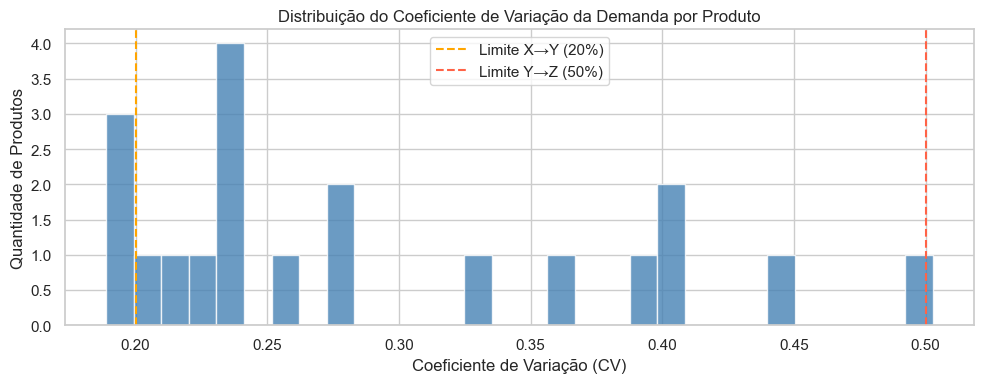

In [5]:
# Distribuição dos CVs
plt.figure(figsize=(10, 4))
plt.hist(cv_produto['cv'], bins=30, color='steelblue', edgecolor='white', alpha=0.8)
plt.axvline(0.20, color='orange', ls='--', label='Limite X→Y (20%)')
plt.axvline(0.50, color='tomato', ls='--', label='Limite Y→Z (50%)')
plt.title('Distribuição do Coeficiente de Variação da Demanda por Produto')
plt.xlabel('Coeficiente de Variação (CV)')
plt.ylabel('Quantidade de Produtos')
plt.legend()
plt.tight_layout()
plt.show()

## Distribuição do Coeficiente de Variação (CV) da Demanda por Produto

### Referência dos Limites de Classificação XYZ

| Limite        | CV       | Cor        | Interpretação                        |
|---------------|----------|------------|--------------------------------------|
| X → Y         | CV = 20% | Laranja    | Acima deste valor: demanda variável  |
| Y → Z         | CV = 50% | Vermelho   | Acima deste valor: demanda caótica   |

---

### Observações do Histograma

**Zona X (CV < 20%) — Alta Previsibilidade:**
- Pouquíssimos produtos abaixo do limite laranja (~3 produtos com CV próximo a 0,18–0,19).
- Confirma que **apenas ~15% do portfólio** tem demanda realmente estável.

**Zona Y (20% ≤ CV < 50%) — Previsibilidade Moderada:**
- **Concentração central da distribuição** — maioria dos produtos se agrupa entre 0,20 e 0,45.
- Pico máximo em **CV ≈ 0,25** com 4 produtos — o bin mais frequente.
- Distribuição razoavelmente espalhada até 0,45, sem forte concentração em nenhum ponto.
- Confirma os **16 produtos Classe Y** identificados no resumo XYZ.

**Zona Z (CV ≥ 50%) — Demanda Imprevisível:**
- **1 produto** exatamente na fronteira de CV = 0,50 — o único Classe Z.
- Caso isolado; não há dispersão além desse ponto.

---

### Conclusão

> A distribuição é **assimétrica à esquerda** — a maioria dos produtos
> opera com CV entre **0,20 e 0,45**, caracterizando um portfólio
> predominantemente **Classe Y com tendência a moderada variabilidade**.
> O único produto **Classe Z (CV = 0,50)** está no limite do critério,
> não sendo um caso extremo, mas ainda assim exige atenção especial
> no planejamento de reposição.
> A ausência de CVs acima de 0,50 é um sinal positivo —
> **não há produtos com demanda verdadeiramente caótica** no portfólio.

## 4. Matriz ABC-XYZ

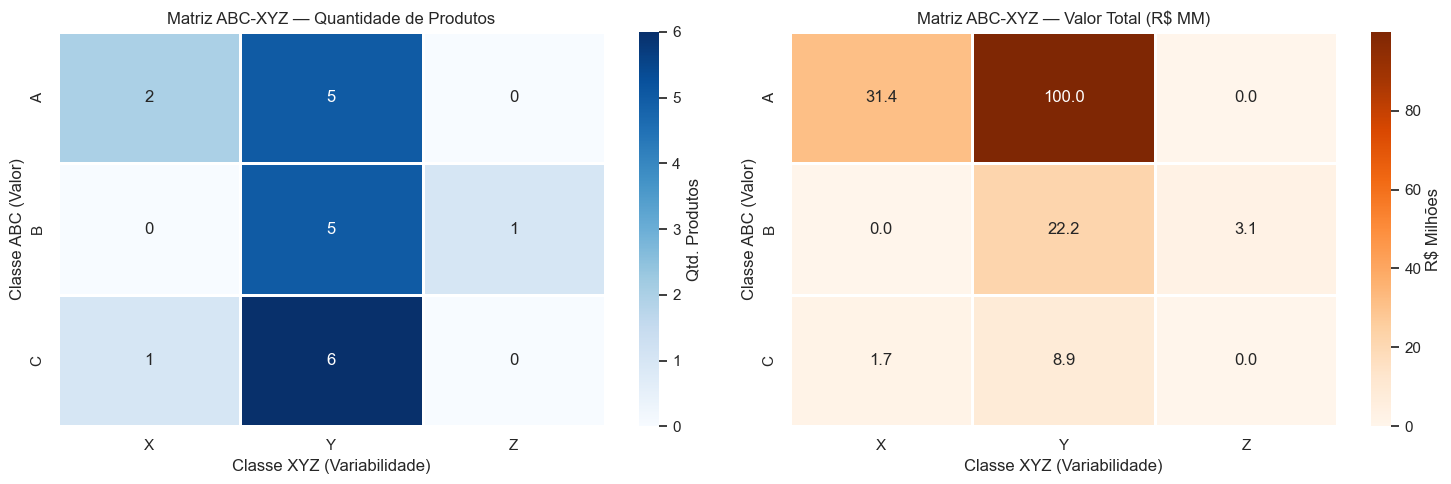

In [6]:
# Combinar ABC e XYZ
abc_xyz = valor_produto[['id_produto', 'produto', 'categoria', 'valor_total', 'classe_abc']].merge(
    cv_produto[['id_produto', 'demanda_media', 'cv', 'classe_xyz']],
    on='id_produto'
)
abc_xyz['classe_abcxyz'] = abc_xyz['classe_abc'] + abc_xyz['classe_xyz']

# Heatmap da matriz
pivot_matriz = abc_xyz.groupby(['classe_abc', 'classe_xyz']).size().unstack(fill_value=0)
pivot_matriz = pivot_matriz.reindex(index=['A', 'B', 'C'], columns=['X', 'Y', 'Z'], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(pivot_matriz, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            linewidths=1, cbar_kws={'label': 'Qtd. Produtos'})
axes[0].set_title('Matriz ABC-XYZ — Quantidade de Produtos')
axes[0].set_xlabel('Classe XYZ (Variabilidade)')
axes[0].set_ylabel('Classe ABC (Valor)')

# Valor por quadrante
pivot_valor = abc_xyz.groupby(['classe_abc', 'classe_xyz'])['valor_total'].sum().unstack(fill_value=0) / 1e6
pivot_valor = pivot_valor.reindex(index=['A', 'B', 'C'], columns=['X', 'Y', 'Z'], fill_value=0)
sns.heatmap(pivot_valor, annot=True, fmt='.1f', cmap='Oranges', ax=axes[1],
            linewidths=1, cbar_kws={'label': 'R$ Milhões'})
axes[1].set_title('Matriz ABC-XYZ — Valor Total (R$ MM)')
axes[1].set_xlabel('Classe XYZ (Variabilidade)')
axes[1].set_ylabel('Classe ABC (Valor)')

plt.tight_layout()
plt.show()

## Matriz ABC-XYZ — Análise Combinada

---

### Matriz 1 — Quantidade de Produtos

|        | X (estável) | Y (variável) | Z (caótico) | **Total** |
|--------|:-----------:|:------------:|:-----------:|:---------:|
| **A**  | 2           | 5            | 0           | **7**     |
| **B**  | 0           | 5            | 1           | **6**     |
| **C**  | 1           | 6            | 0           | **7**     |
| **Total** | **3**    | **16**       | **1**       | **20**    |

---

### Matriz 2 — Valor Total (R$ MM)

|        | X (estável) | Y (variável) | Z (caótico) | **Total**    |
|--------|:-----------:|:------------:|:-----------:|:------------:|
| **A**  | R$ 31,4 MM  | R$ 100,0 MM  | R$ 0,0 MM   | **R$ 131,4 MM** |
| **B**  | R$ 0,0 MM   | R$ 22,2 MM   | R$ 3,1 MM   | **R$ 25,3 MM**  |
| **C**  | R$ 1,7 MM   | R$ 8,9 MM    | R$ 0,0 MM   | **R$ 10,6 MM**  |

---

### Análise por Quadrante Estratégico

**🔴 AY — Crítico e Prioritário (5 produtos | R$ 100,0 MM)**
- O quadrante de maior risco: **alto valor + demanda variável**.
- Concentra **~60% de todo o valor do portfólio** em apenas 5 produtos.
- Exige **forecast ativo, estoque de segurança robusto e monitoramento contínuo**.

**🟠 AX — Alto Valor e Previsível (2 produtos | R$ 31,4 MM)**
- Situação ideal para itens de alta relevância financeira.
- Demanda estável permite **reposição automatizada e lean**.
- Baixo esforço de gestão para alto retorno.

**🟡 BY — Valor Intermediário e Variável (5 produtos | R$ 22,2 MM)**
- Grupo relevante que demanda atenção periódica.
- Risco moderado — revisão mensal de demanda recomendada.

**🔵 BZ — Risco Oculto (1 produto | R$ 3,1 MM)**
- Único produto Classe Z: valor intermediário com demanda imprevisível.
- Candidato a **compra sob demanda** para evitar excesso ou ruptura.

**⚪ CY — Baixo Valor e Variável (6 produtos | R$ 8,9 MM)**
- Maior grupo em quantidade, menor impacto financeiro.
- Candidatos à **simplificação de gestão ou compra consolidada**.

---

### Priorização de Gestão

| Prioridade | Quadrante | Ação Recomendada                              |
|:----------:|-----------|-----------------------------------------------|
| 1          | **AY**    | Forecast avançado + estoque de segurança alto |
| 2          | **AX**    | Reposição automática + ponto de pedido fixo   |
| 3          | **BY**    | Revisão periódica de demanda                  |
| 4          | **BZ**    | Compra sob demanda / contrato de reserva      |
| 5          | **CY/CX** | Gestão simplificada / lote consolidado        |

---

### Conclusão

> O portfólio tem seu risco concentrado no quadrante **AY**:
> poucos produtos, enorme valor financeiro e demanda difícil de prever.
> A combinação ABC-XYZ revela que **gerir bem 5 produtos (AY)**
> é suficiente para controlar ~60% do valor total da cadeia.

## 5. Recomendações de Política por Quadrante

## Políticas de Reposição por Quadrante ABC-XYZ

| Quadrante | Perfil | Política Recomendada |
|:---------:|--------|----------------------|
| **AX** | Alto valor + demanda estável | Reposição contínua, estoque de segurança baixo, EOQ exato |
| **AY** | Alto valor + variabilidade moderada | Monitoramento frequente, estoque de segurança médio |
| **AZ** | Alto valor + alta variabilidade | Reposição just-in-time, revisão periódica semanal |
| **BX** | Valor médio + demanda estável | Reposição periódica, EOQ simplificado |
| **BY** | Valor médio + variabilidade moderada | Revisão bimestral, estoque de segurança médio |
| **BZ** | Valor médio + alta variabilidade | Compras por demanda, evitar estoque excessivo |
| **CX** | Baixo valor + demanda estável | Lote máximo, revisão anual, custo de pedido alto relativo |
| **CY** | Baixo valor + variabilidade moderada | Reposição semestral ou consignado |
| **CZ** | Baixo valor + alta variabilidade | Consolidar com fornecedor, compra spot ou eliminar SKU |

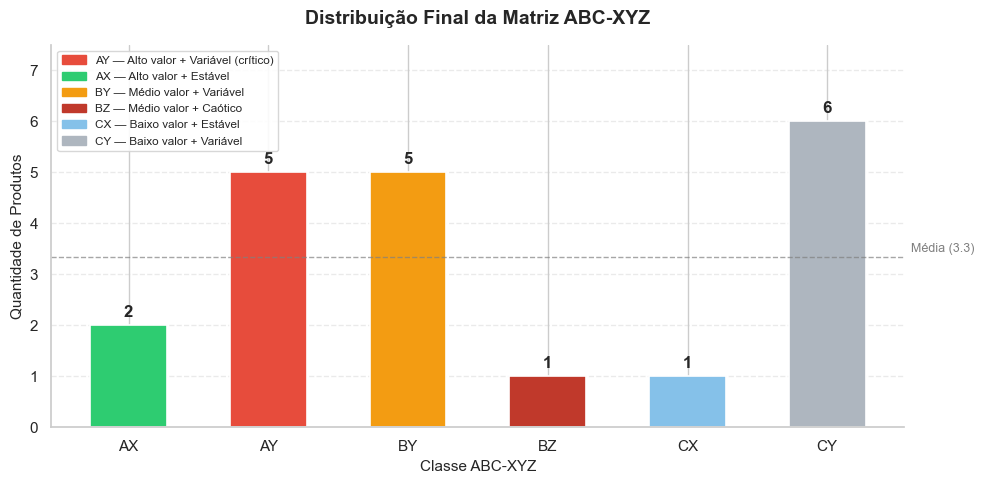

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

classes = ['AX', 'AY', 'BY', 'BZ', 'CX', 'CY']
quantidades = [2, 5, 5, 1, 1, 6]

cores = {
    'AX': '#2ecc71',   # verde — alto valor, estável
    'AY': '#e74c3c',   # vermelho — alto valor, variável (crítico)
    'BY': '#f39c12',   # laranja — médio valor, variável
    'BZ': '#c0392b',   # vermelho escuro — médio valor, caótico
    'CX': '#85c1e9',   # azul claro — baixo valor, estável
    'CY': '#aeb6bf',   # cinza — baixo valor, variável
}

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(classes,
              quantidades,
              color=[cores[c] for c in classes],
              edgecolor='white',
              linewidth=1.2,
              width=0.55)

# Rótulos em cima das barras
for bar, qty in zip(bars, quantidades):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            str(qty),
            ha='center', va='bottom',
            fontsize=12, fontweight='bold')

# Linha de referência da média
media = sum(quantidades) / len(quantidades)
ax.axhline(media, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax.text(len(classes) - 0.4, media + 0.1, f'Média ({media:.1f})',
        fontsize=9, color='gray')

ax.set_title('Distribuição Final da Matriz ABC-XYZ', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Classe ABC-XYZ', fontsize=11)
ax.set_ylabel('Quantidade de Produtos', fontsize=11)
ax.set_ylim(0, 7.5)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)

# Legenda
legenda = [
    mpatches.Patch(color='#e74c3c', label='AY — Alto valor + Variável (crítico)'),
    mpatches.Patch(color='#2ecc71', label='AX — Alto valor + Estável'),
    mpatches.Patch(color='#f39c12', label='BY — Médio valor + Variável'),
    mpatches.Patch(color='#c0392b', label='BZ — Médio valor + Caótico'),
    mpatches.Patch(color='#85c1e9', label='CX — Baixo valor + Estável'),
    mpatches.Patch(color='#aeb6bf', label='CY — Baixo valor + Variável'),
]
ax.legend(handles=legenda, fontsize=8.5, loc='upper left',
          framealpha=0.9, edgecolor='lightgray')

plt.tight_layout()
plt.show()

In [8]:
# Salvar resultado
abc_xyz.to_csv('data/classificacao_abc_xyz.csv', index=False)
print(f'Arquivo salvo: data/classificacao_abc_xyz.csv ({len(abc_xyz)} produtos)')

print('\n=== Distribuição final da Matriz ABC-XYZ ===')
display(abc_xyz['classe_abcxyz'].value_counts().sort_index())

Arquivo salvo: data/classificacao_abc_xyz.csv (20 produtos)

=== Distribuição final da Matriz ABC-XYZ ===


classe_abcxyz
AX    2
AY    5
BY    5
BZ    1
CX    1
CY    6
Name: count, dtype: int64

In [9]:
# Resumo de produtos por segmento ABC-XYZ
resumo_produtos = (
    abc_xyz[['classe_abcxyz', 'classe_abc', 'classe_xyz', 'produto', 'categoria', 'valor_total', 'cv']]
    .sort_values(['classe_abcxyz', 'valor_total'], ascending=[True, False])
    .copy()
)
resumo_produtos['valor_total'] = resumo_produtos['valor_total'].map('R$ {:,.0f}'.format)
resumo_produtos['cv']          = resumo_produtos['cv'].map('{:.1%}'.format)
resumo_produtos.columns        = ['Segmento', 'ABC', 'XYZ', 'Produto', 'Categoria', 'Valor Total', 'CV']
resumo_produtos = resumo_produtos.reset_index(drop=True)

print('=== Produtos por Segmentação ABC-XYZ ===\n')
for seg, grupo in resumo_produtos.groupby('Segmento', sort=True):
    print(f'── {seg} ─────────────────────────────────────────')
    display(grupo[['Produto', 'Categoria', 'Valor Total', 'CV']].reset_index(drop=True))
    print()

=== Produtos por Segmentação ABC-XYZ ===

── AX ─────────────────────────────────────────


,Produto,Categoria,Valor Total,CV
0,Selante Silicone 280mL,Materiais,"R$ 25,072,571",18.9%
1,Parafuso Aço Inox M8,Fixadores,"R$ 6,288,747",18.9%



── AY ─────────────────────────────────────────


,Produto,Categoria,Valor Total,CV
0,Luva de Proteção CA,EPI,"R$ 48,178,251",23.7%
1,Óculos de Segurança,EPI,"R$ 22,428,352",21.4%
2,Protetor Auricular,EPI,"R$ 12,619,411",24.0%
3,Filtro de Linha Industrial,Eletroeletrônicos,"R$ 9,820,132",40.0%
4,Capacete de Segurança,EPI,"R$ 6,949,521",27.8%



── BY ─────────────────────────────────────────


...

,Produto,Categoria,Valor Total,CV
0,Motor Elétrico 1CV,Eletroeletrônicos,"R$ 3,064,235",50.3%



── CX ─────────────────────────────────────────


,Produto,Categoria,Valor Total,CV
0,Arruela Lisa M8,Fixadores,"R$ 1,679,119",19.2%



── CY ─────────────────────────────────────────


,Produto,Categoria,Valor Total,CV
0,"Chave de Fenda 1/4""",Ferramentas,"R$ 2,777,432",27.6%
1,Chave Allen 5mm,Ferramentas,"R$ 2,354,219",23.3%
2,Cabo de Aço 6mm (m),Materiais,"R$ 1,395,194",25.4%
3,Tubo PVC 100mm (m),Materiais,"R$ 1,156,831",22.2%
4,Tinta Epóxi 18L,Materiais,"R$ 928,830",36.4%
5,Martelo Cabo Borracha,Ferramentas,"R$ 253,936",39.2%


## Resumo Executivo — Análise ABC-XYZ

---

### Concentração de Valor (Curva ABC)

- **7 produtos (35% do portfólio) respondem por 78,6% do valor total consumido**
  — padrão de Pareto clássico confirmado pela curva acumulada.
- A Classe A movimenta **R$ 131,4 MM**, enquanto as Classes B e C juntas
  somam apenas **R$ 35,9 MM**.
- Fixadores e EPI são as categorias de maior valor absoluto consumido,
  com EPI liderando também em **custo logístico total (~R$ 5,1 MM)**.

---

### Previsibilidade de Demanda (Curva XYZ)

- **80% dos produtos são Classe Y** — demanda variável e moderadamente
  imprevisível — exigindo planejamento de forecast ativo na maior parte do portfólio.
- Apenas **3 produtos (15%) têm demanda estável (Classe X)**,
  os únicos candidatos à reposição automatizada sem risco.
- **1 produto Classe Z** (CV = 50%) opera no limite da imprevisibilidade —
  deve ser gerido sob demanda para evitar ruptura ou excesso.

---

### Quadrante Crítico — AY

- O cruzamento ABC-XYZ revela que **5 produtos concentram R$ 100 MM (≈60% do valor total)**
  com demanda variável — o maior risco financeiro e operacional do portfólio.
- Esses 5 itens **AY devem ser a prioridade absoluta** de gestão:
  forecast avançado, estoque de segurança robusto e monitoramento contínuo.
- Os 2 produtos **AX (R$ 31,4 MM)** são a exceção positiva: alto valor
  com demanda previsível — candidatos à automação de reposição.

---

### Riscos Combinados

- **EPI lidera em valor consumido, taxa de ruptura (6,5%) e custo logístico**
  — é a categoria de maior exposição em toda a cadeia.
- Os picos de ruptura ocorrem sistematicamente no **T4 (Out–Dez)**,
  coincidindo com o período de maior demanda — risco previsível e evitável.
- Produtos de **alto giro têm taxa de ruptura de 3,8%**,
  reforçando que os itens Classe A são os mais vulneráveis a desabastecimento.

---

### Recomendações Prioritárias

- **Focar esforço de planejamento nos 5 produtos AY** — são poucos itens,
  mas concentram a maior parte do valor e do risco simultaneamente.
- **Antecipar compras no T3** para os itens Classe A, evitando o padrão
  recorrente de pico de ruptura no T4.
- **Automatizar reposição dos produtos AX e CX** — demanda estável
  não justifica esforço manual de planejamento.
- **Revisar estoque de segurança de EPI e Materiais**, as duas categorias
  com maior taxa de ruptura e alto volume de demanda.
- **Avaliar o produto BZ** para contrato de reserva ou compra sob demanda,
  eliminando o risco de excesso de estoque por imprevisibilidade.

> **Próxima etapa:** Análise de Desempenho de Fornecedores — Scorecard OTIF.